In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [5]:
logistics = Path(r"..\dataset\raw\Logistics SCM.csv")   # Event Log; ID_Case, Activity, Timestamp

df = pd.read_csv(logistics, sep=",")    # Separate with ; 
df = df.rename(columns={"Expedision Type": "Expedition Type"})

print("Event log loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Event log loaded successfully!
Rows: 99
Columns: 4


,Case ID,Duration,Expedition Type,Province
0,190710123661H8U,4013,3,2
1,190720055566T5G,6457,3,9
2,19072506336Q7QX,3633,1,5
3,190725102165JA2,6235,1,9
4,19073015476M26F,3955,1,2


In [48]:
print(df.columns.tolist())
print(df.dtypes)

print(f"\nMissing Values: \n{df.isna().sum()}")
display(df.describe().T)

['Case ID', 'Duration', 'Expedition Type', 'Province']
Case ID              str
Duration           int64
Expedition Type    int64
Province           int64
dtype: object

Missing Values: 
Case ID            0
Duration           0
Expedition Type    0
Province           0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Duration,99.0,6744.646465,15896.378845,1458.0,3179.5,4356.0,6346.0,155245.0
Expedition Type,99.0,1.616162,1.184139,1.0,1.0,1.0,2.0,7.0
Province,99.0,3.424242,2.308330,1.0,2.0,3.0,5.0,9.0


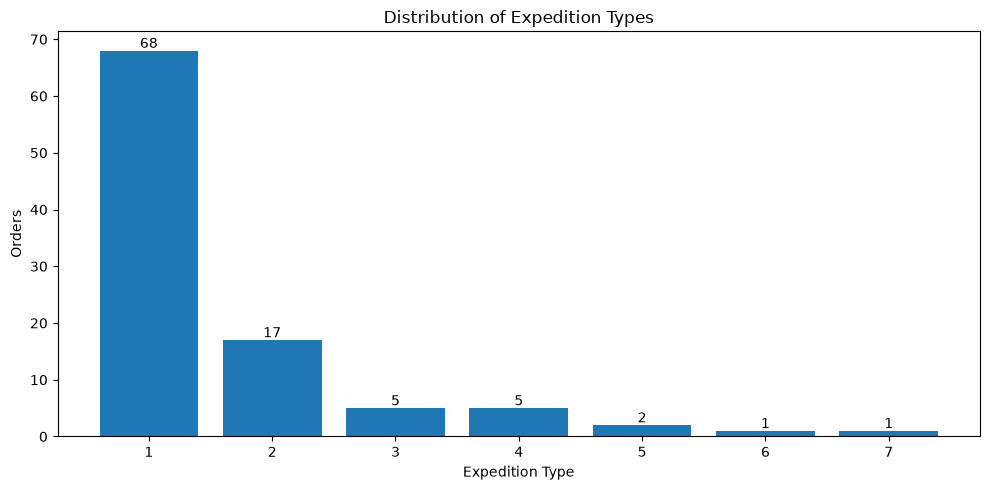

In [97]:
expedition_count = df['Expedition Type'].value_counts().sort_index()

e_x = expedition_count.index.astype(str)
e_y = expedition_count.values

def add_labels(x, y, height):
    for i in range(len(x)):
        if height == 'top':
            h = y[i] + 0.5
        else:
            h = y[i] // 2

        plt.text(
            i,
            h,
            y[i],
            ha='center'
        )

plt.figure(figsize=(10, 5))
plt.bar(e_x, e_y)
add_labels(e_x, e_y, 'top')

plt.title("Distribution of Expedition Types")
plt.xlabel("Expedition Type")
plt.ylabel("Orders")

plt.tight_layout()
plt.show()


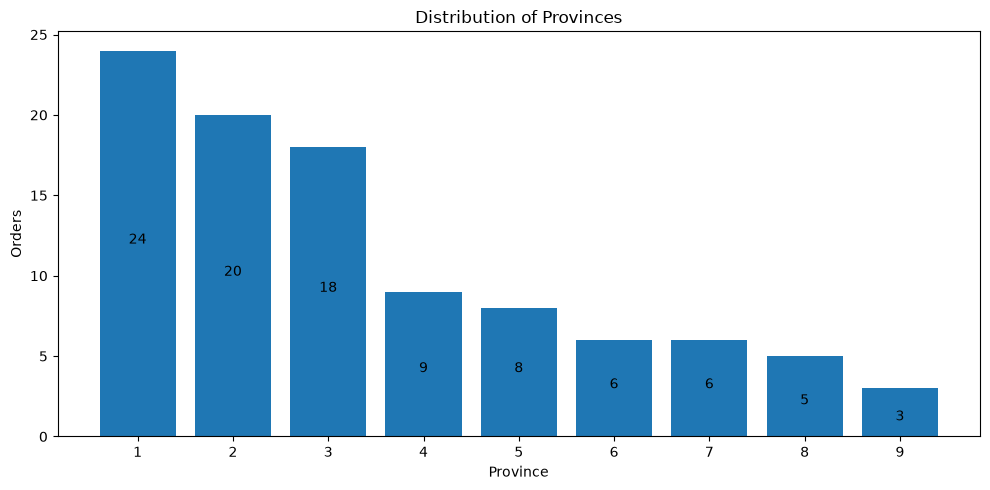

In [98]:
Province_count = df['Province'].value_counts().sort_index()

p_x = Province_count.index.astype(str)
p_y = Province_count.values

plt.figure(figsize=(10, 5))
plt.bar(p_x, p_y)
add_labels(p_x, p_y, 'middle')

plt.title("Distribution of Provinces")
plt.xlabel("Province")
plt.ylabel("Orders")

plt.tight_layout()
plt.show()


Note : Duration in minutes

  Statistic       Duration  Duration_hours
0      mean    6744.646465          112.41
1       min    1458.000000           24.30
2       max  155245.000000         2587.42


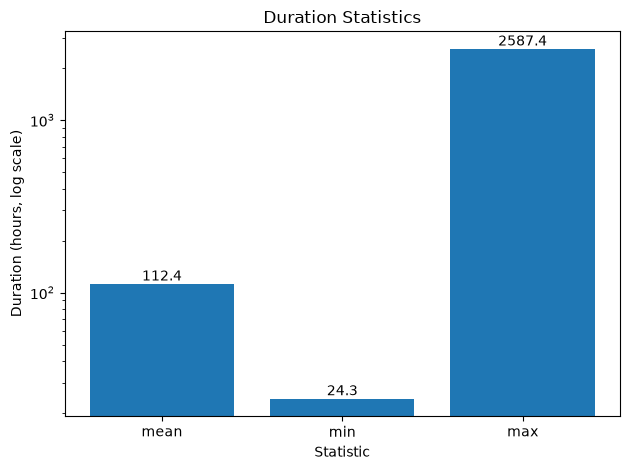

In [ ]:
# Get duration stats
stats = df['Duration'].describe()[['mean', 'min', 'max']]
stats_df = stats.rename_axis('Statistic').reset_index(name='Duration')

# Change to minutes to hours
stats_df['Duration_hours'] = (stats_df['Duration'] / 60).round(2)

print(stats_df)

# Plot graph
bars = plt.bar(stats_df['Statistic'], stats_df['Duration_hours'])

plt.yscale('log')
plt.title('Duration Statistics')
plt.xlabel('Statistic')
plt.ylabel('Duration (hours, log scale)')

plt.bar_label(bars, fmt='%.1f')
plt.tight_layout()
plt.show()